In [3]:
import pandas as pd
import numpy as np
import os 

In [10]:
# Load the TSV file into a DataFrame
df = pd.read_csv("Data/Restaurant_Reviews.tsv", sep="\t")


In [11]:
df.head(5)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [12]:
df.isnull().sum()

Review    0
Liked     0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(4)

In [15]:

df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [16]:
df.dtypes

Review      str
Liked     int64
dtype: object

In [17]:
df.describe()

,Liked
count,996.000000
mean,0.501004
std,0.500250
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [18]:
df.shape

(996, 2)

In [23]:
X = df[['Review']]   # Input
Y = df['Liked']        # Output

In [24]:
X

,Review
0,Wow... Loved this place.
1,Crust is not good.
2,Not tasty and the texture was just nasty.
3,Stopped by during the late May bank holiday of...
4,The selection on the menu was great and so wer...
...,...
995,I think food should have flavor and texture an...
996,Appetite instantly gone.
997,Overall I was not impressed and would not go b...
998,"The whole experience was underwhelming, and I ..."


In [25]:
Y

0      1
1      0
2      0
3      1
4      1
      ..
995    0
996    0
997    0
998    0
999    0
Name: Liked, Length: 996, dtype: int64

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X_encoded = vectorizer.fit_transform(X['Review'])

In [27]:
X_encoded

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 9767 stored elements and shape (996, 2035)>

In [31]:
X_encoded.shape

(996, 2035)

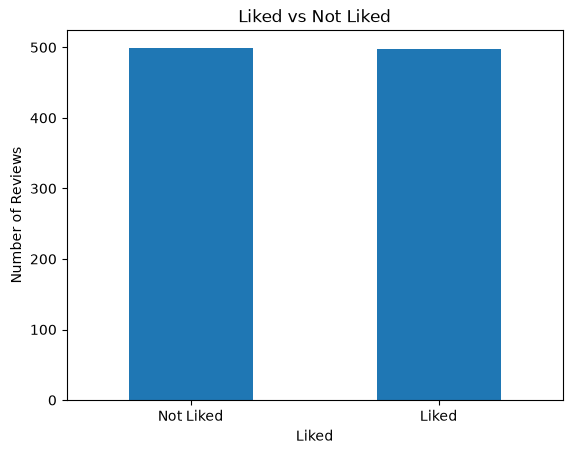

In [32]:
import matplotlib.pyplot as plt

df['Liked'].value_counts().plot(kind='bar')

plt.xlabel('Liked')
plt.ylabel('Number of Reviews')
plt.title('Liked vs Not Liked')
plt.xticks([0, 1], ['Not Liked', 'Liked'], rotation=0)
plt.show()

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    Y,
    test_size=0.2,
    random_state=42
)

In [35]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[391.,405.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.71,-0.68]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2035)","[[0. ,0.49,0.34,...,0.41,0.25,1.27], [0. ,0. ,0.53,...,0. ,1.14,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 2035)","[[-8.07,-7.67,-7.77,...,-7.72,-7.84,-7.24], [-8.06,-8.06,-7.63,...,-8.06,-7.3 ,-8.06]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2035


In [36]:
y_pred = model.predict(X_test)

In [37]:
y_pred

array([1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 0])

In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.79


In [39]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[89 17]
 [25 69]]
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       106
           1       0.80      0.73      0.77        94

    accuracy                           0.79       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.79      0.79      0.79       200



In [40]:
import joblib

joblib.dump(model, 'naive_bayes_model.pkl')

['naive_bayes_model.pkl']

In [41]:
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

In [42]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [43]:
lr_pred

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0])

In [44]:
accuracy = accuracy_score(y_test, lr_pred)

print("Accuracy:", accuracy)

Accuracy: 0.815


In [45]:
print(confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

[[98  8]
 [29 65]]
              precision    recall  f1-score   support

           0       0.77      0.92      0.84       106
           1       0.89      0.69      0.78        94

    accuracy                           0.81       200
   macro avg       0.83      0.81      0.81       200
weighted avg       0.83      0.81      0.81       200



In [46]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

In [47]:
svm_pred

array([1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       0, 0])

In [49]:
accuracy = accuracy_score(y_test, svm_pred)
print("Accuracy", accuracy)

Accuracy 0.815


In [50]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)


In [53]:
accuracy = accuracy_score(y_test, dt_pred)
print("Accuracy:", accuracy)

Accuracy: 0.71


In [54]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier( n_estimators=100,
    random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)


In [55]:
rf_pred

array([1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 0])

In [57]:
accuracy = accuracy_score(y_test, rf_pred)
print("Accuracy", accuracy)

Accuracy 0.775


In [58]:
print("Naivebayes:", accuracy_score(y_test, y_pred))
print("Decision Tree:", accuracy_score(y_test, dt_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))
print("SVM:", accuracy_score(y_test, svm_pred))
print("LogisticRegression:", accuracy_score(y_test, lr_pred))

Naivebayes: 0.79
Decision Tree: 0.71
Random Forest: 0.775
SVM: 0.815
LogisticRegression: 0.815


In [59]:
import joblib

joblib.dump(svm_model, "svm_model.pkl")

['svm_model.pkl']

In [61]:
from pathlib import Path
import sys

# Create logs folder
Path("logs").mkdir(exist_ok=True)

# Log file
log_file = Path("logs/training_log.txt")

print("Logging started...")
print("Log file:", log_file)

Logging started...
Log file: logs\training_log.txt


In [ ]:
import sys
from pathlib import Path

class Logger:
    def __init__(self, filename):
        self.terminal = sys.stdout
        self.log = open(filename, "a", encoding="utf-8")

    def write(self, message):
        self.terminal.write(message)
        self.log.write(message)
        self.log.flush()

    def flush(self):
        self.terminal.flush()
        self.log.flush()

sys.stdout = Logger("logs/training_log.txt")

print("Training started")

Training started


SVM model trained successfully
Accuracy: 0.81
[1]


In [63]:
print("SVM model trained successfully")
print("Accuracy:", 0.81)

In [67]:
import joblib

# Load saved files
model = joblib.load("C:/Users/ADEEL/Desktop/ML_practice/Models/svm_model.pkl")
vectorizer = joblib.load("C:/Users/ADEEL/Desktop/ML_practice/Models/tfidf_vectorizer.pkl")

# New user input
text = ["I really enjoyed this movie"]

# Convert text using SAME TF-IDF vectorizer
text_vectorized = vectorizer.transform(text)

# Prediction
prediction = model.predict(text_vectorized)

print(prediction)